# Image segmentation on urban street scenes

This notebook currently contains:
- **Dataset exploration**: basic checks to understand the dataset structure and visualization of images with their binary masks.
- **Part 1.1: per-pixel classification**: a simple classifier (logistic regression) that predicts, from the RGB values of a single pixel, whether it belongs to the sky or not (binary segmentation: sky vs. everything else).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (7, 7)

import skimage
import skimage.io

In [2]:
IMG_DIR = "dataset/Cityscape Dataset/leftImg8bit"
MASK_DIR = "dataset/Fine Annotations/gtFine"

CLASS_NAMES = [
    "unlabeled", "ego vehicle", "rectification border", "out of roi", "static",
    "dynamic", "ground", "road", "sidewalk", "parking", "rail track",
    "building", "wall", "fence", "guard rail", "bridge", "tunnel", "pole",
    "polegroup", "traffic light", "traffic sign", "vegetation", "terrain",
    "sky", "person", "rider", "car", "truck", "bus", "caravan", "trailer",
    "train", "motorcycle", "bicycle",
]

SKY_ID = 23

## 0. Dataset exploration

In this section we explore the dataset to understand how it is organized and what the masks contain.

In [3]:
name = "zurich_000016_000019"
im = skimage.io.imread(f"{IMG_DIR}/train/zurich/{name}_leftImg8bit.png")
ids = skimage.io.imread(f"{MASK_DIR}/train/zurich/{name}_gtFine_labelIds.png")

print(im.shape, im.dtype)
print(ids.shape, ids.dtype, np.unique(ids))

(1024, 2048, 3) uint8
(1024, 2048) uint8 [ 1  3  4  5  7  8 11 12 17 20 21 23 24 25 26 33]


In [4]:
# Every class present in the image
for i in np.unique(ids):
    print(i, CLASS_NAMES[i])

1 ego vehicle
3 out of roi
4 static
5 dynamic
7 road
8 sidewalk
11 building
12 wall
17 pole
20 traffic sign
21 vegetation
23 sky
24 person
25 rider
26 car
33 bicycle


### Images and binary masks

We visualize the first 10 training images of Zurich next to their binary sky masks.

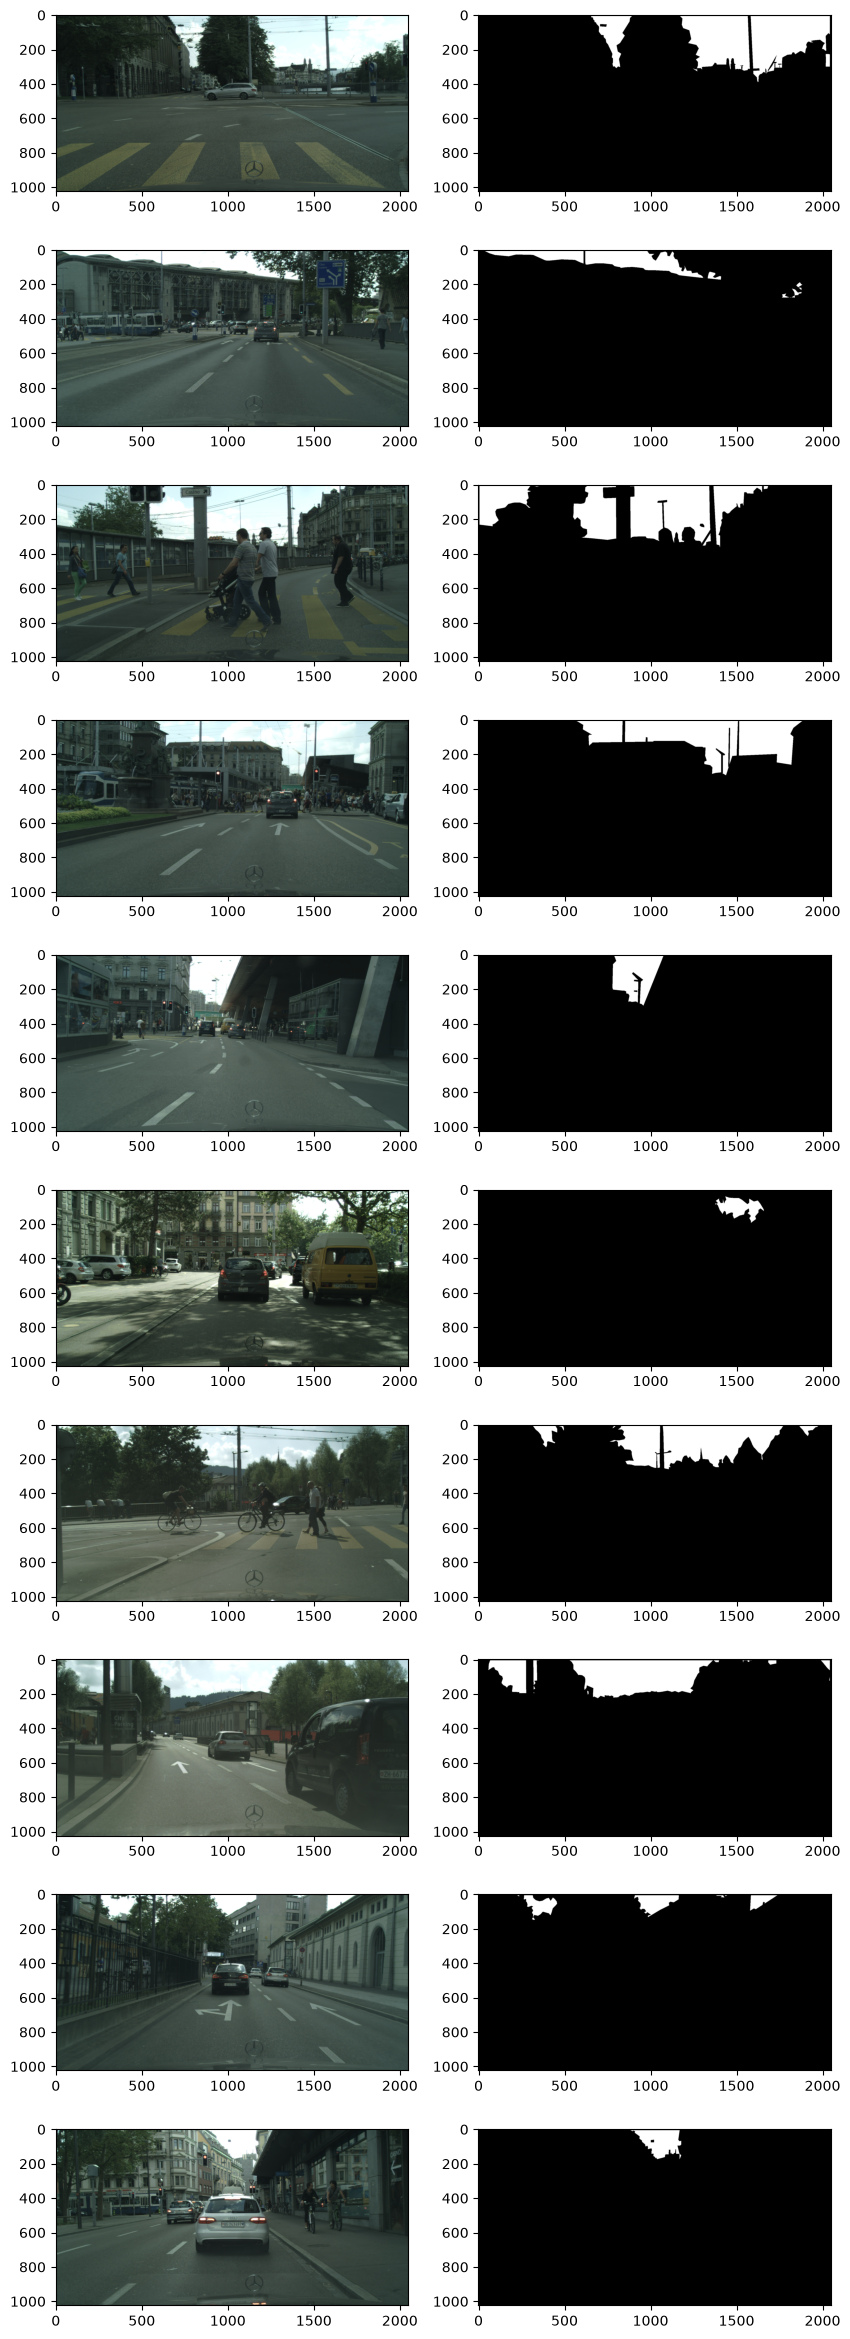

In [5]:
fig, axs = plt.subplots(nrows=10, ncols=2, figsize=(10, 30))

for i in range(10):
    name = f"zurich_{i:06d}_000019"
    im_i = skimage.io.imread(f"{IMG_DIR}/train/zurich/{name}_leftImg8bit.png")
    ids_i = skimage.io.imread(f"{MASK_DIR}/train/zurich/{name}_gtFine_labelIds.png")
    sky_mask = ids_i == SKY_ID

    axs[i, 0].imshow(im_i)
    axs[i, 1].imshow(sky_mask, cmap="gray", vmin=0, vmax=1)

plt.show()